Dataset shape: (891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Survival counts:


,count
survived,
Did not survive,549
Survived,342



Passenger class counts:


,count
class,
Third,491
First,216
Second,184



Sex counts:


,count
sex,
male,577
female,314


,missing_count,missing_percent
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


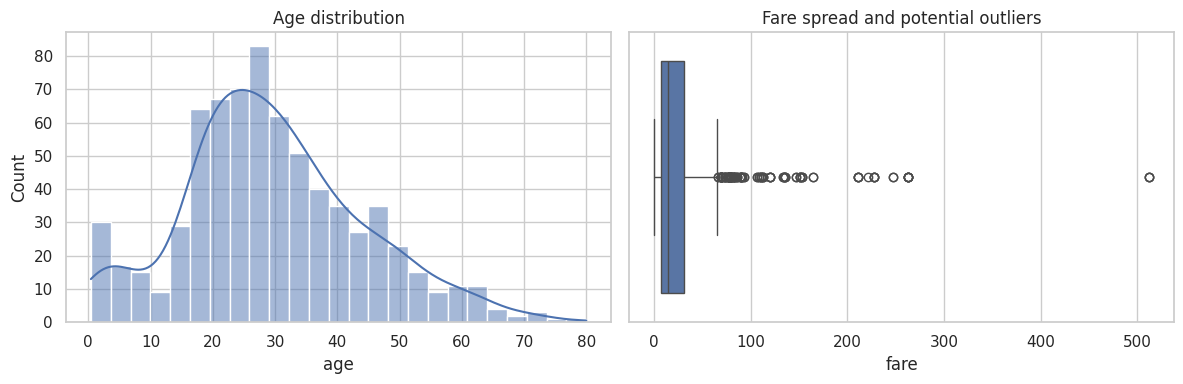

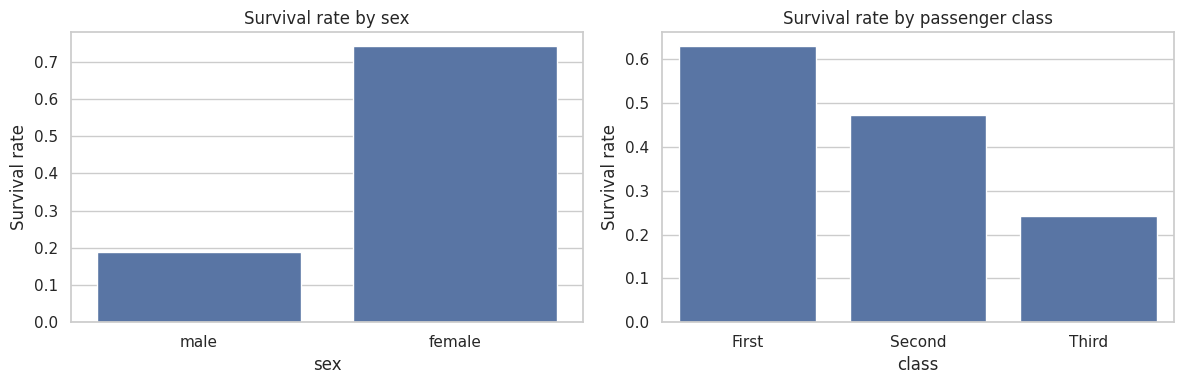

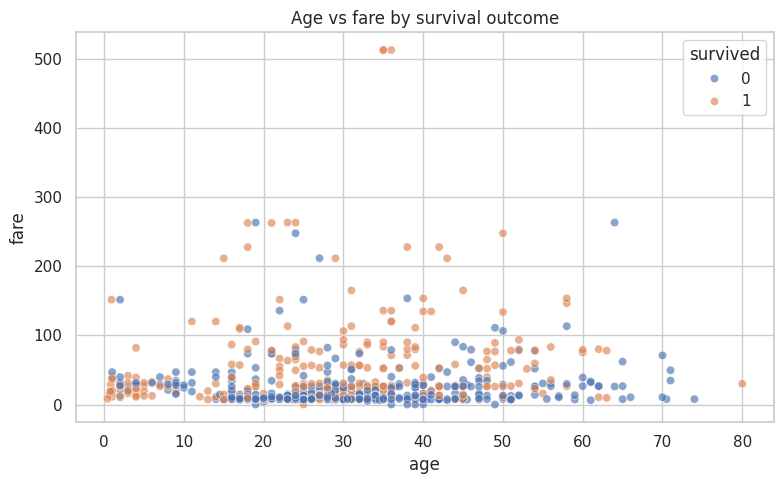

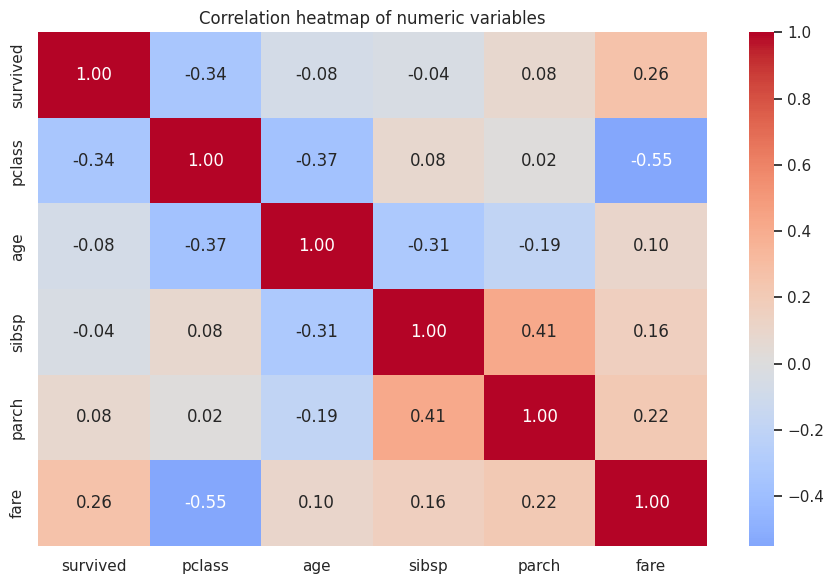

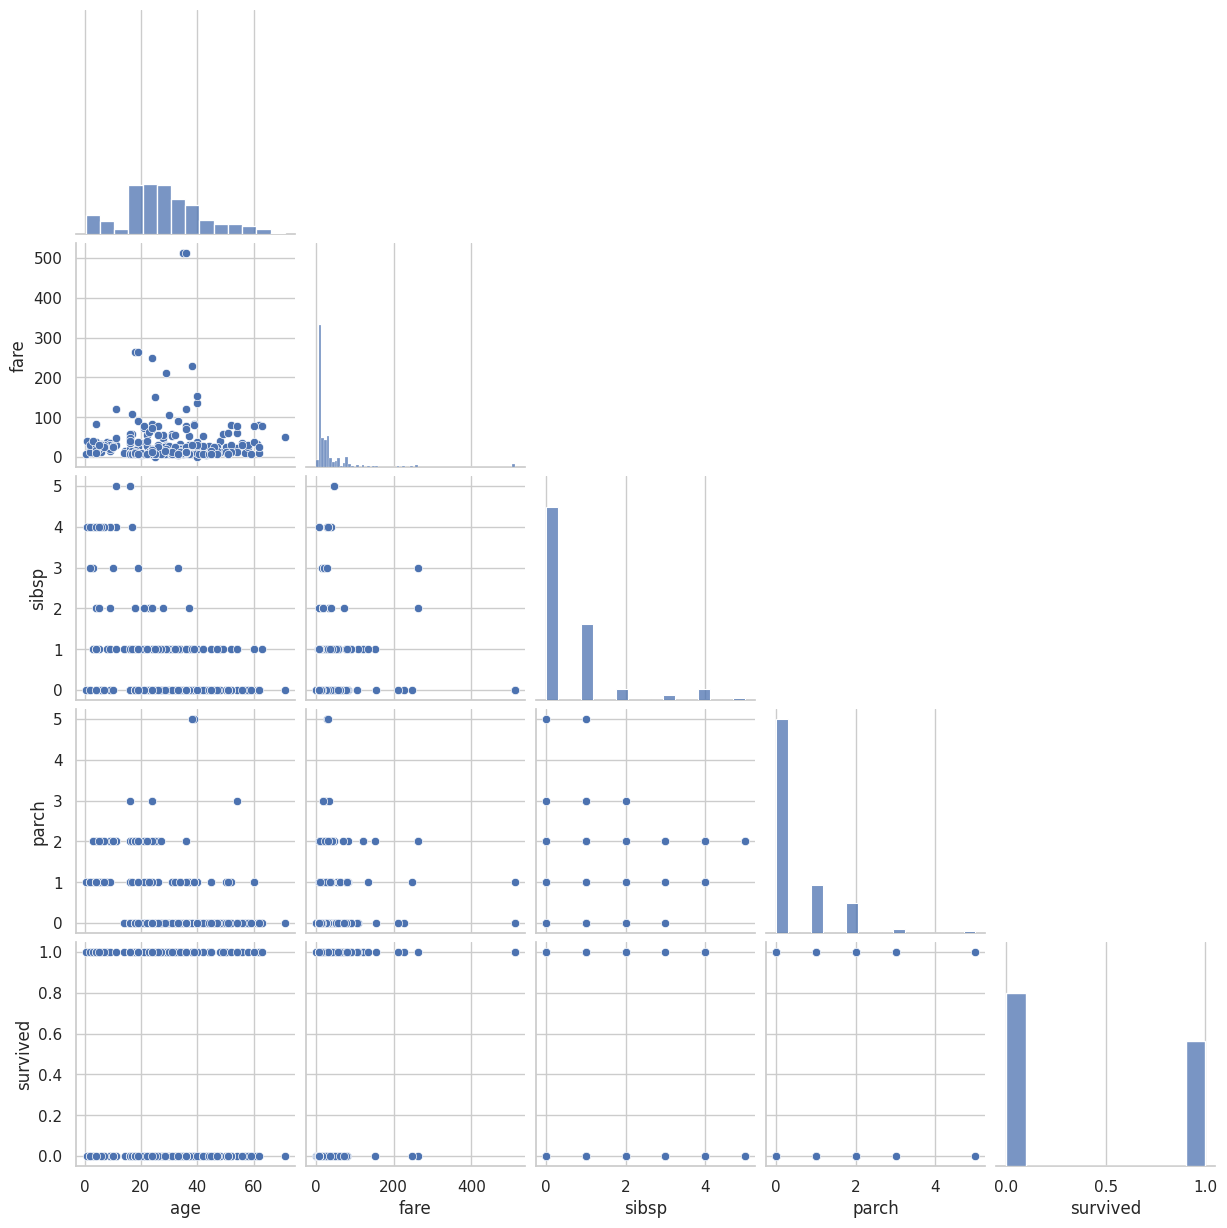

In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

# Prefer the included local CSV; download from the public source if it is not present.
if os.path.exists("titanic.csv"):
    df = pd.read_csv("titanic.csv")
else:
    df = pd.read_csv(DATA_URL)

print("Dataset shape:", df.shape)
df.head()
df.info()
display(df.describe(include="all").T)
print("Survival counts:")
display(df["survived"].value_counts().rename(index={0: "Did not survive", 1: "Survived"}))
print("\nPassenger class counts:")
display(df["class"].value_counts())
print("\nSex counts:")
display(df["sex"].value_counts())
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing[missing["missing_count"] > 0])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["age"].dropna(), bins=25, kde=True, ax=axes[0])
axes[0].set_title("Age distribution")
sns.boxplot(x=df["fare"].dropna(), ax=axes[1])
axes[1].set_title("Fare spread and potential outliers")
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=df, x="sex", y="survived", errorbar=None, ax=axes[0])
axes[0].set_title("Survival rate by sex")
axes[0].set_ylabel("Survival rate")
sns.barplot(data=df, x="class", y="survived", order=["First", "Second", "Third"], errorbar=None, ax=axes[1])
axes[1].set_title("Survival rate by passenger class")
axes[1].set_ylabel("Survival rate")
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="age", y="fare", hue="survived", alpha=0.65)
plt.title("Age vs fare by survival outcome")
plt.tight_layout()
plt.show()
numeric = df.select_dtypes(include="number")
plt.figure(figsize=(9, 6))
sns.heatmap(numeric.corr(), annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation heatmap of numeric variables")
plt.tight_layout()
plt.show()
pair_cols = [c for c in ["age", "fare", "sibsp", "parch", "survived"] if c in df.columns]
sns.pairplot(df[pair_cols].dropna().sample(min(300, len(df[pair_cols].dropna())), random_state=42),
             corner=True, diag_kind="hist")
plt.show()